In [1]:
import pandas as pd

caminho_dados="../data/raw/Online Retail.xlsx"

df=pd.read_excel(caminho_dados)

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
print("Este é o seu documento", df.shape)


df.info()

Este é o seu documento (541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [3]:
# Gerar estatísticas descritivas das colunas numéricas (Quantity e UnitPrice)
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303


In [4]:
# 1. Filtrar o DataFrame mantendo apenas vendas com quantidade e preço estritamente positivos
df_limpo = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)].copy()

# 2. Comparar o número de linhas antes e depois do filtro
print(f"Linhas originais: {df.shape[0]:,}")
print(f"Linhas após a remoção de valores <= 0: {df_limpo.shape[0]:,}")
print(f"Registros removidos: {df.shape[0] - df_limpo.shape[0]:,}")

Linhas originais: 541,909
Linhas após a remoção de valores <= 0: 530,104
Registros removidos: 11,805


In [5]:
# 1. Criar a coluna de faturamento calculando o valor total por item
df_limpo['TotalSales'] = df_limpo['Quantity'] * df_limpo['UnitPrice']

# 2. Exibir o faturamento total acumulado da empresa na base
faturamento_total = df_limpo['TotalSales'].sum()
print(f"Faturamento Total Comercial: £ {faturamento_total:,.2f}")

# 3. Visualizar as primeiras linhas com a nova coluna
df_limpo[['InvoiceNo', 'Description', 'Quantity', 'UnitPrice', 'TotalSales']].head()

Faturamento Total Comercial: £ 10,666,684.54


,InvoiceNo,Description,Quantity,UnitPrice,TotalSales
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30
1,536365,WHITE METAL LANTERN,6,3.39,20.34
2,536365,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34


In [6]:
# 1. Agrupar por país, somar o faturamento e ordenar do maior para o menor
faturamento_por_pais = (
    df_limpo.groupby('Country')['TotalSales']
    .sum()
    .sort_values(ascending=False)
)

# 2. Converter para DataFrame e calcular a porcentagem da receita total
top5_paises = faturamento_por_pais.head(5).to_frame(name='Faturamento_Total')
top5_paises['Representatividade_%'] = (top5_paises['Faturamento_Total'] / df_limpo['TotalSales'].sum()) * 100

# 3. Exibir o resultado formatado
print("=== TOP 5 PAÍSES POR FATURAMENTO ===")
print(top5_paises.to_string(formatters={
    'Faturamento_Total': '£ {:,.2f}'.format,
    'Representatividade_%': '{:.2f}%'.format
}))

=== TOP 5 PAÍSES POR FATURAMENTO ===
               Faturamento_Total Representatividade_%
Country                                              
United Kingdom    £ 9,025,222.08               84.61%
Netherlands         £ 285,446.34                2.68%
EIRE                £ 283,453.96                2.66%
Germany             £ 228,867.14                2.15%
France              £ 209,715.11                1.97%


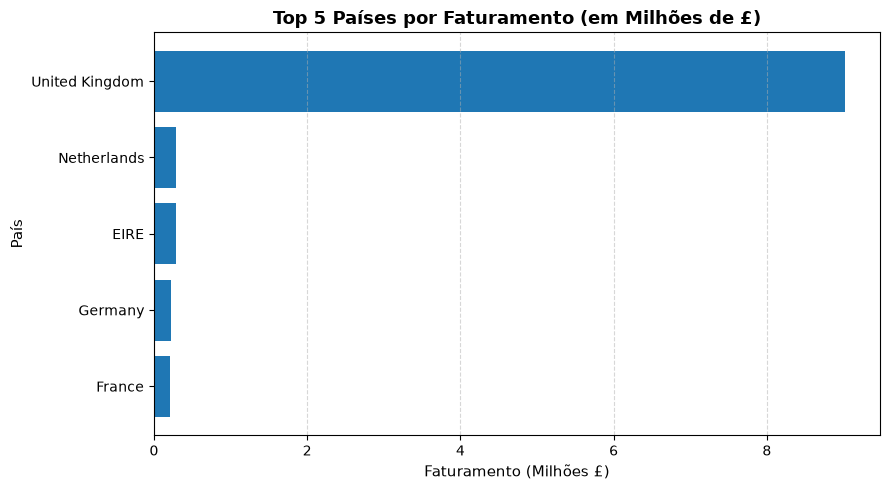

In [7]:
import matplotlib.pyplot as plt

# 1. Preparar os dados para plotagem (invertendo a ordem para o maior ficar no topo)
dados_grafico = top5_paises['Faturamento_Total'].sort_values(ascending=True)

# 2. Criar a figura do gráfico
plt.figure(figsize=(9, 5))
barras = plt.barh(dados_grafico.index, dados_grafico / 1000000, color='#1f77b4')

# 3. Adicionar títulos e rótulos
plt.title('Top 5 Países por Faturamento (em Milhões de £)', fontsize=13, fontweight='bold')
plt.xlabel('Faturamento (Milhões £)', fontsize=11)
plt.ylabel('País', fontsize=11)

# 4. Ajustar layout e exibir
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [8]:
# 1. Agrupar por produto, somar a receita e ordenar
top5_produtos = (
    df_limpo.groupby('Description')['TotalSales']
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .reset_index()
)

# 2. Renomear as colunas para exibição amigável
top5_produtos.columns = ['Produto', 'Faturamento_Total']

# 3. Exibir o resultado formatado em Libras (£)
print("=== TOP 5 PRODUTOS MAIS RENTÁVEIS ===")
for index, row in top5_produtos.iterrows():
    print(f"{index + 1}. {row['Produto']}: £ {row['Faturamento_Total']:,.2f}")

=== TOP 5 PRODUTOS MAIS RENTÁVEIS ===
1. DOTCOM POSTAGE: £ 206,248.77
2. REGENCY CAKESTAND 3 TIER: £ 174,484.74
3. PAPER CRAFT , LITTLE BIRDIE: £ 168,469.60
4. WHITE HANGING HEART T-LIGHT HOLDER: £ 106,292.77
5. PARTY BUNTING: £ 99,504.33


In [9]:
# 1. Definir o caminho de destino dentro da pasta data/processed/
caminho_saida = '../data/processed/online_retail_cleaned.csv'

# 2. Exportar o DataFrame para CSV sem salvar o índice do Pandas
df_limpo.to_csv(caminho_saida, index=False, encoding='utf-8')

print("Arquivo limpo e exportado com sucesso para:")
print(caminho_saida)

Arquivo limpo e exportado com sucesso para:
../data/processed/online_retail_cleaned.csv
